# Day 2 — Black–Scholes Pricing & Greeks

**Implied Volatility Surface & Options Analysis** · Notebook 02

### Where we are
**Notebook 01 (Day 1)** downloaded SPY and AAPL option chains, cleaned them with six filters, checked
the no-arbitrage bounds and put–call parity, and saved `data/clean_SPY.csv`, `data/clean_AAPL.csv`
and `data/market_meta.json`.

### Objective of today
Build a **Black–Scholes pricer** and its **Greeks** that work on single numbers *and* on whole pandas
columns, and **prove it is correct** with tests. Day 3 uses this pricer as an engine: implied
volatility is simply "the $\sigma$ that makes `bs_price` equal the market price".

| Section | What it does |
|---|---|
| 1 | Load the Day 1 files (no yfinance) |
| 2 | Check the data: shapes, types, missing values, duplicates, `T`, `mid`, zero bids, `iv_yahoo` |
| 3 | Black–Scholes formula → `bs_price` |
| 4 | Greeks → `bs_greeks` |
| 5 | Tests: put–call parity, finite differences, Monte Carlo |
| 6 | Plots: Delta and Gamma vs spot |
| 7 | Bridge to Day 3: price is increasing in $\sigma$ |
| 8 | Summary and the decisions left for Day 3 |

## 1. Setup and Load the Cleaned Data

Black–Scholes needs five market inputs. Four come straight from our files:

| Input | Symbol | Where it comes from |
|---|---|---|
| Spot price | $S$ | column `spot` |
| Strike | $K$ | column `strike` |
| Time to expiry (years) | $T$ | column `T` |
| Risk-free rate | $r$ | `market_meta.json` (13-week T-bill `^IRX`, saved on Day 1) |
| Volatility | $\sigma$ | **unknown** — this is what Day 3 solves for |

`yfinance` is **not** imported: this notebook only reads the CSV files, so re-running it never
downloads anything.

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)

# Project folders (works whether the notebook runs from src/ or the project root)
ROOT = Path.cwd().parent if Path.cwd().name == "src" else Path.cwd()
DATA_DIR = ROOT / "data"
FIG_DIR = ROOT / "figures"

TICKERS = ["SPY", "AAPL"]
DATE_COLS = ["expiry", "download_date", "download_time"]   # CSV stores dates as text -> parse them

clean_data = {t: pd.read_csv(DATA_DIR / f"clean_{t}.csv", parse_dates=DATE_COLS) for t in TICKERS}

meta = json.loads((DATA_DIR / "market_meta.json").read_text())
r = meta["r"]

print(f"risk-free rate r = {r:.4f}  (13-week T-bill, saved on Day 1)")
for t, d in clean_data.items():
    print(f"{t:5s} rows = {len(d):5d}   columns = {d.shape[1]}   spot = {d['spot'].iloc[0]:8.2f}   "
          f"expiries = {d['expiry'].nunique()}   downloaded = {d['download_time'].iloc[0]:%Y-%m-%d %H:%M}")

risk-free rate r = 0.0408  (13-week T-bill, saved on Day 1)
SPY   rows =  1225   columns = 16   spot =   769.05   expiries = 9   downloaded = 2026-10-21 18:19
AAPL  rows =   270   columns = 16   spot =   339.50   expiries = 9   downloaded = 2026-10-21 18:19


**Line by line**
- `from scipy.stats import norm` — `norm.cdf(x)` is $N(x)$, the standard normal CDF in the
  Black–Scholes formula; `norm.pdf(x)` is $\varphi(x)$, the bell-curve density used by the Greeks.
- `ROOT`, `DATA_DIR`, `FIG_DIR` — same folder logic as Notebook 01.
- `parse_dates=DATE_COLS` — without it `expiry` would be text and `expiry - download_date` would fail.
- `clean_data` — a dict: `clean_data["SPY"]` is the SPY table (same name as in Notebook 01).
- `r` — annual, continuously-compounded rate as a decimal (0.0408 = 4.08 % per year). Because it is
  *annual*, $T$ must be in *years* so that $e^{-rT}$ makes sense.

## 2. Check the Data Before Using It

We never feed data into a formula before checking it. Four questions:
1. Shape, data types, missing values, duplicates — is the file what we think it is?
2. Is `T` really measured in **years**?
3. How was `mid` built — is it really $(\text{bid}+\text{ask})/2$?
4. Is `iv_yahoo` a trustworthy reference?

In [2]:
overview = pd.DataFrame({
    t: {"rows": d.shape[0],
        "columns": d.shape[1],
        "missing values": int(d.isna().sum().sum()),
        "duplicate rows": int(d.duplicated().sum()),
        "duplicate contracts": int(d["contractSymbol"].duplicated().sum()),
        "calls": int((d["type"] == "call").sum()),
        "puts": int((d["type"] == "put").sum())}
    for t, d in clean_data.items()})
display(overview)

print("Missing values per column (only columns with at least one):")
missing = pd.DataFrame({t: d.isna().sum() for t, d in clean_data.items()})
display(missing[missing.sum(axis=1) > 0])

print("Data types:")
print(clean_data["SPY"].dtypes.to_string())

,SPY,AAPL
rows,1225,270
columns,16,16
missing values,10,1
duplicate rows,0,0
duplicate contracts,0,0
calls,439,130
puts,786,140


Missing values per column (only columns with at least one):


,SPY,AAPL
volume,10,1


Data types:
contractSymbol            object
strike                   float64
bid                      float64
ask                      float64
lastPrice                float64
volume                   float64
openInterest               int64
iv_yahoo                 float64
type                      object
expiry            datetime64[ns]
ticker                    object
spot                     float64
download_date     datetime64[ns]
download_time     datetime64[ns]
T                        float64
mid                      float64


**What to look for**
- `duplicate contracts = 0` — every `contractSymbol` (one option = one ticker + expiry + type + strike)
  appears once, so no option is counted twice.
- The only missing values are in `volume` (no trade today). `volume` is **not** a Black–Scholes input,
  so these rows are kept.
- `expiry`, `download_date`, `download_time` are `datetime64` — the parsing worked.

In [3]:
cols = ["contractSymbol", "type", "strike", "expiry", "T", "spot", "bid", "ask", "lastPrice", "mid", "iv_yahoo"]
for t, d in clean_data.items():
    print(f"===== {t}: first 5 rows =====")
    display(d[cols].head(5))

===== SPY: first 5 rows =====


,contractSymbol,type,strike,expiry,T,spot,bid,ask,lastPrice,mid,iv_yahoo
0,SPY261030C00770000,call,770.0,2026-10-30,0.024658,769.049988,0.0,0.0,7.35,7.35,0.001963
1,SPY261030C00771000,call,771.0,2026-10-30,0.024658,769.049988,0.0,0.0,6.70,6.70,0.003916
2,SPY261030C00772000,call,772.0,2026-10-30,0.024658,769.049988,0.0,0.0,6.10,6.10,0.007822
3,SPY261030C00773000,call,773.0,2026-10-30,0.024658,769.049988,0.0,0.0,5.54,5.54,0.007822
4,SPY261030C00774000,call,774.0,2026-10-30,0.024658,769.049988,0.0,0.0,5.15,5.15,0.007822


===== AAPL: first 5 rows =====


,contractSymbol,type,strike,expiry,T,spot,bid,ask,lastPrice,mid,iv_yahoo
0,AAPL261106C00340000,call,340.0,2026-11-06,0.043836,339.5,0.0,0.0,8.95,8.95,0.001963
1,AAPL261106C00345000,call,345.0,2026-11-06,0.043836,339.5,0.0,0.0,6.47,6.47,0.015635
2,AAPL261106C00350000,call,350.0,2026-11-06,0.043836,339.5,0.0,0.0,4.50,4.50,0.031260
3,AAPL261106C00355000,call,355.0,2026-11-06,0.043836,339.5,0.0,0.0,3.04,3.04,0.062509
4,AAPL261106C00360000,call,360.0,2026-11-06,0.043836,339.5,0.0,0.0,1.96,1.96,0.062509


### 2.1 Is `T` measured in years?

Notebook 01 built it as `T = (expiry - download_date).days / 365`. We recompute it and compare.

In [4]:
for t, d in clean_data.items():
    days = (d["expiry"] - d["download_date"]).dt.days      # calendar days to expiry
    T_check = days / 365.0                                    # convert to years
    max_diff = (d["T"] - T_check).abs().max()
    print(f"{t:5s} max |T - days/365| = {max_diff:.1e}   "
          f"T from {d['T'].min():.4f} to {d['T'].max():.4f} years  ({days.min()} to {days.max()} days)")

SPY   max |T - days/365| = 2.2e-16   T from 0.0247 to 1.6548 years  (9 to 604 days)
AAPL  max |T - days/365| = 6.2e-17   T from 0.0438 to 1.6548 years  (16 to 604 days)


A difference of (practically) zero confirms: **`T` is in years, measured in calendar days / 365 from
the download date.** Example: 9 days → $T = 9/365 \approx 0.0247$.

### 2.2 How was `mid` built? Zero bids and asks

The textbook mid price is $(\text{bid}+\text{ask})/2$. We count how many rows actually satisfy that, and
how many have a usable quote at all.

In [5]:
rows = []
for t, d in clean_data.items():
    rows.append({
        "ticker": t,
        "rows": len(d),
        "bid = 0": int((d["bid"] <= 0).sum()),
        "ask = 0": int((d["ask"] <= 0).sum()),
        "valid quote (bid>0, ask>bid)": int(((d["bid"] > 0) & (d["ask"] > d["bid"])).sum()),
        "mid = (bid+ask)/2": int(np.isclose(d["mid"], (d["bid"] + d["ask"]) / 2).sum()),
        "mid = lastPrice": int(np.isclose(d["mid"], d["lastPrice"]).sum()),
    })
mid_check = pd.DataFrame(rows).set_index("ticker")
mid_check

,rows,bid = 0,ask = 0,"valid quote (bid>0, ask>bid)",mid = (bid+ask)/2,mid = lastPrice
ticker,,,,,,
SPY,1225,1213,1213,12,0,1225
AAPL,270,270,270,0,0,270


**What this shows.** The data were downloaded at about 18:19 Phnom Penh time, when the US market was
**closed**. yfinance then returns `bid = ask = 0` for almost every contract, so Notebook 01 (cell 5)
replaced `mid` by `lastPrice` — the price of the **last trade**, which may have happened hours or
days earlier. So in these files **`mid` is really `lastPrice`**, not a bid–ask mid.

Only a handful of SPY rows have a real quote. They let us measure how far the last trade is from the
true mid:

In [6]:
spy = clean_data["SPY"]
live = spy[(spy["bid"] > 0) & (spy["ask"] > spy["bid"])].copy()
live["true_mid"] = (live["bid"] + live["ask"]) / 2
live["lastPrice - true_mid"] = live["lastPrice"] - live["true_mid"]
live["lastPrice > ask"] = live["lastPrice"] > live["ask"]
display(live[["contractSymbol", "type", "strike", "expiry", "bid", "ask", "true_mid",
              "lastPrice", "lastPrice - true_mid", "lastPrice > ask", "volume", "iv_yahoo"]])
print(f"median gap lastPrice - true_mid = {live['lastPrice - true_mid'].median():.2f} "
      f"({(live['lastPrice - true_mid'] / live['true_mid']).median():.0%} of the mid)")

,contractSymbol,type,strike,expiry,bid,ask,true_mid,lastPrice,lastPrice - true_mid,lastPrice > ask,volume,iv_yahoo
849,SPY270331P00589000,put,589.0,2027-03-31,4.81,4.85,4.830,6.52,1.690,True,NaN,0.288429
850,SPY270331P00599000,put,599.0,2027-03-31,5.65,5.69,5.670,7.94,2.270,True,1.0,0.285560
851,SPY270331P00602000,put,602.0,2027-03-31,9.11,9.15,9.130,12.59,3.460,True,250.0,0.321677
852,SPY270331P00603000,put,603.0,2027-03-31,6.84,6.89,6.865,9.77,2.905,True,2.0,0.294624
871,SPY270331P00646000,put,646.0,2027-03-31,15.16,15.26,15.210,17.85,2.640,True,4.0,0.303382
874,SPY270331P00667000,put,667.0,2027-03-31,12.22,12.28,12.250,17.00,4.750,True,1.0,0.244697
960,SPY270630P00669000,put,669.0,2027-06-30,17.86,17.94,17.900,25.02,7.120,True,NaN,0.226051
964,SPY270630P00673000,put,673.0,2027-06-30,16.39,16.47,16.430,18.44,2.010,True,4.0,0.212174
970,SPY270630P00681000,put,681.0,2027-06-30,19.72,19.81,19.765,27.84,8.075,True,1.0,0.218666
1005,SPY270630P00729000,put,729.0,2027-06-30,29.42,29.54,29.480,38.50,9.020,True,NaN,0.188714


median gap lastPrice - true_mid = 4.11 (36% of the mid)


**Why this matters for implied volatility (Day 3).**
- Where a real quote exists, the last trade is **above the ask** — a price nobody was offering at
  download time. It is stale: it belongs to a different moment (and a different spot) than the
  `spot` column.
- Implied volatility is the $\sigma$ that makes Black–Scholes equal the price we give it. Give it a
  stale price and we get a stale (here: too high) IV. For deep OTM options, whose price is small, a
  gap of a few dollars changes the IV a lot.
- A **zero bid** means "nobody wants to buy this option right now". A zero bid with a zero ask means
  "no quote at all" — there is no market price to invert.

**Nothing is deleted here.** On Day 2 we only test the pricer on chosen inputs, so the data quality
does not change today's results. The decision is for Day 3 (see Section 8).

### 2.3 Is `iv_yahoo` a trustworthy reference?

`iv_yahoo` is Yahoo's own implied volatility. We use it only as a **reference to compare against**,
never as our result. First check what values it takes:

In [7]:
for t, d in clean_data.items():
    top = d["iv_yahoo"].round(6).value_counts().head(6)
    print(f"{t}: the 6 most common values cover {top.sum() / len(d):.0%} of {len(d)} rows")
    print(top.to_string(), "\n")
print("Compare with powers of 2:", [round(2.0**-n, 6) for n in range(2, 8)])

SPY: the 6 most common values cover 93% of 1225 rows
iv_yahoo
0.062509    301
0.031260    300
0.125009    232
0.015635    167
0.007822     78
0.250008     57 

AAPL: the 6 most common values cover 95% of 270 rows
iv_yahoo
0.062509    75
0.031260    60
0.125009    57
0.015635    32
0.250008    18
0.007822    15 

Compare with powers of 2: [0.25, 0.125, 0.0625, 0.03125, 0.015625, 0.007812]


**What this shows.** Almost all `iv_yahoo` values sit (to 4 decimals) on $1/4, 1/8, 1/16, 1/32, 1/64, \dots$ — values a
search algorithm produces when it stops without a valid price, not real market volatilities. Only the
few SPY rows with a live bid/ask (table in 2.2) have realistic-looking values (about 16 %–32 %).
So for **this snapshot**, `iv_yahoo` is not a reliable benchmark, except on those live rows.

---
**Check your understanding (Section 2)**
1. If `T` had been stored in *days* instead of years, would a Black–Scholes price come out too high or too low? Why?
2. Why is a `lastPrice` above the `ask` a sign that the price is stale?
3. Why can't we compute an implied volatility for an option whose bid and ask are both 0 and that never traded?

## 3. The Black–Scholes Formula

### Idea in plain words
Black–Scholes assumes the stock price moves randomly with a **constant volatility** $\sigma$ (how much
it wiggles per year). Under that assumption the fair price of a European option is the **expected
payoff at expiry, discounted to today** with the risk-free rate.

### The formula (with dividend yield $q$)
$$
d_1 = \frac{\ln(S/K) + (r - q + \tfrac12\sigma^2)\,T}{\sigma\sqrt{T}}, \qquad d_2 = d_1 - \sigma\sqrt{T}
$$
$$
C = S e^{-qT} N(d_1) - K e^{-rT} N(d_2), \qquad
P = K e^{-rT} N(-d_2) - S e^{-qT} N(-d_1)
$$

| Piece | Meaning |
|---|---|
| $K e^{-rT}$ | present value of the strike (you pay $K$ later, so it is discounted with $r$) |
| $S e^{-qT}$ | present value of the stock **without** the dividends paid before expiry (the option holder does not get them) |
| $N(d_2)$ | risk-neutral probability that the call ends in the money ($S_T > K$) |
| $N(d_1)$ | the call's Delta (before the $e^{-qT}$ factor); how many shares hedge one call |
| $\sigma\sqrt{T}$ | total uncertainty until expiry: grows with volatility *and* with time |

### What is $q$, and what value do we use?
$q$ is the continuous **dividend yield**. SPY and AAPL both pay dividends, but we have **not**
measured $q$ yet, and we will not guess it. Day 3 estimates it from market prices with put–call parity
(the *implied forward*). Today the functions take `q` as an input, and the tests use chosen values.

### Simplifications to keep in mind
- European exercise (SPY and AAPL options are American; the difference is small for the OTM options we keep).
- Constant $r$, $q$ and $\sigma$ until expiry. The market contradicts constant $\sigma$ — that is exactly
  why we will see a *smile* on Day 4.

In [8]:
def _arr(*xs):
    # Convert numbers, lists or pandas columns to float numpy arrays (so one function handles all)
    return [np.asarray(x, dtype=float) for x in xs]


def bs_d1_d2(S, K, T, r, q, sigma):
    S, K, T, sigma = _arr(S, K, T, sigma)
    vsqrt = sigma * np.sqrt(T)                                   # sigma * sqrt(T): total uncertainty
    d1 = (np.log(S / K) + (r - q + 0.5 * sigma**2) * T) / vsqrt
    return d1, d1 - vsqrt


def bs_price(S, K, T, r, q, sigma, kind="call"):
    # Black-Scholes price of a European call or put; kind can be one string or a column of "call"/"put"
    d1, d2 = bs_d1_d2(S, K, T, r, q, sigma)
    S, K, T = _arr(S, K, T)
    disc_r, disc_q = np.exp(-r * T), np.exp(-q * T)              # discount factors e^{-rT}, e^{-qT}
    call = S * disc_q * norm.cdf(d1) - K * disc_r * norm.cdf(d2)
    put = K * disc_r * norm.cdf(-d2) - S * disc_q * norm.cdf(-d1)
    return np.where(np.asarray(kind) == "call", call, put)

**Line by line**
- `_arr` — turns any input (a number like `100.0`, or a whole column like `df["strike"]`) into a numpy
  array, so the same code prices one option or a thousand at once (*vectorised*).
- `bs_d1_d2` — computes $d_1$ and $d_2$ exactly as in the formula. `np.log` is the natural log $\ln$.
- `disc_r = np.exp(-r * T)` — the factor that turns a payment at $T$ into today's money (present value).
- `call`, `put` — both prices are computed; `np.where(kind == "call", call, put)` picks the right one
  row by row. That is what lets us pass the `type` column later.
- **Output:** a numpy array of prices (use `float(...)` to get a plain number for one option).

### Sanity check against a textbook example
Hull, *Options, Futures, and Other Derivatives* (Example 15.6): $S=42$, $K=40$, $r=10\%$, $\sigma=20\%$,
$T=0.5$, no dividends gives $C \approx 4.76$ and $P \approx 0.81$.

In [9]:
c_hull = float(bs_price(42, 40, 0.5, 0.10, 0.0, 0.20, "call"))
p_hull = float(bs_price(42, 40, 0.5, 0.10, 0.0, 0.20, "put"))
print(f"call = {c_hull:.4f}   (textbook 4.76)")
print(f"put  = {p_hull:.4f}   (textbook 0.81)")

# Vectorised: three strikes in one call
print("calls for K = 38, 40, 42:", bs_price(42, [38, 40, 42], 0.5, 0.10, 0.0, 0.20, "call").round(4))

call = 4.7594   (textbook 4.76)
put  = 0.8086   (textbook 0.81)
calls for K = 38, 40, 42: [6.2606 4.7594 3.4767]


**Expected:** call ≈ 4.76 and put ≈ 0.81, and the three call prices **fall** as the strike rises
(the right to buy at a higher price is worth less) — the same shape as the Day 1 plot.

---
**Check your understanding (Section 3)**
1. In $C = Se^{-qT}N(d_1) - Ke^{-rT}N(d_2)$, which term is "what you receive" and which is "what you pay"?
2. If $\sigma$ goes up, does $\sigma\sqrt{T}$ go up or down? What do you expect for the option price?
3. Tiny exercise: change `T` from 0.5 to 1.0 in the Hull example. Does the call get more or less expensive? Why?

## 4. The Greeks

The Greeks measure **how the option price reacts** when one input changes, all else fixed.
($\varphi$ = standard normal density, `norm.pdf`.)

| Greek | Measures the change in price when… | Call | Put |
|---|---|---|---|
| **Delta** $\partial V/\partial S$ | spot rises by 1 | $e^{-qT}N(d_1)$ | $-e^{-qT}N(-d_1)$ |
| **Gamma** $\partial^2 V/\partial S^2$ | how fast Delta changes | $\dfrac{e^{-qT}\varphi(d_1)}{S\sigma\sqrt{T}}$ | same |
| **Vega** $\partial V/\partial \sigma$ | volatility rises by 1 (= 100 vol points) | $S e^{-qT}\varphi(d_1)\sqrt{T}$ | same |
| **Theta** $\partial V/\partial t$ | one year passes | $-\dfrac{Se^{-qT}\varphi(d_1)\sigma}{2\sqrt{T}} - rKe^{-rT}N(d_2) + qSe^{-qT}N(d_1)$ | $-\dfrac{Se^{-qT}\varphi(d_1)\sigma}{2\sqrt{T}} + rKe^{-rT}N(-d_2) - qSe^{-qT}N(-d_1)$ |
| **Rho** $\partial V/\partial r$ | the rate rises by 1 (= 100 %) | $KTe^{-rT}N(d_2)$ | $-KTe^{-rT}N(-d_2)$ |

**Key fact for Day 3:** Vega $= Se^{-qT}\varphi(d_1)\sqrt{T}$ is **always positive** (a density times
positive numbers). So the price always rises when $\sigma$ rises, and each market price matches
**exactly one** volatility — the implied volatility.

In [10]:
def bs_greeks(S, K, T, r, q, sigma, kind="call"):
    d1, d2 = bs_d1_d2(S, K, T, r, q, sigma)
    S, K, T, sigma = _arr(S, K, T, sigma)
    disc_r, disc_q = np.exp(-r * T), np.exp(-q * T)
    pdf, sqT = norm.pdf(d1), np.sqrt(T)
    is_call = np.asarray(kind) == "call"

    delta = np.where(is_call, disc_q * norm.cdf(d1), -disc_q * norm.cdf(-d1))
    gamma = disc_q * pdf / (S * sigma * sqT)                     # same for calls and puts
    vega = S * disc_q * pdf * sqT                                # same for calls and puts
    decay = -S * disc_q * pdf * sigma / (2 * sqT)                # time-decay part shared by both
    theta = np.where(is_call,
                     decay - r * K * disc_r * norm.cdf(d2) + q * S * disc_q * norm.cdf(d1),
                     decay + r * K * disc_r * norm.cdf(-d2) - q * S * disc_q * norm.cdf(-d1))
    rho = np.where(is_call, K * T * disc_r * norm.cdf(d2), -K * T * disc_r * norm.cdf(-d2))
    return {"delta": delta, "gamma": gamma, "vega": vega, "theta": theta, "rho": rho}

**Line by line**
- `pdf = norm.pdf(d1)` — $\varphi(d_1)$, reused by Gamma, Vega and Theta.
- `is_call` — True/False per row, so `np.where` picks the call or put formula.
- Gamma and Vega have **one** formula: a call and a put with the same strike differ by a forward
  (put–call parity), and a forward has no curvature and no volatility exposure.
- `decay` — the part of Theta caused by volatility; it is negative for both (options lose time value).
- **Output:** a dict of arrays, e.g. `g["vega"]`.

**Units.** Vega and Theta come out per 1.00 change (100 vol points / one year). Traders usually quote
Vega per **1 vol point** (divide by 100) and Theta per **day** (divide by 365):

In [11]:
ex = dict(S=42, K=40, T=0.5, r=0.10, q=0.0, sigma=0.20)      # same Hull example as above
greek_table = pd.DataFrame({kind: {k: float(v) for k, v in bs_greeks(**ex, kind=kind).items()}
                            for kind in ["call", "put"]})
greek_table.loc["vega per 1 vol pt"] = greek_table.loc["vega"] / 100
greek_table.loc["theta per day"] = greek_table.loc["theta"] / 365
greek_table.round(4)

,call,put
delta,0.7791,-0.2209
gamma,0.0500,0.0500
vega,8.8134,8.8134
theta,-4.5591,-0.7542
rho,13.9820,-5.0425
vega per 1 vol pt,0.0881,0.0881
theta per day,-0.0125,-0.0021


**How to read it (call column):** Delta ≈ 0.78 means the call gains about \$0.78 when the stock rises
\$1. Vega per vol point ≈ 0.09 means the call gains about \$0.09 if volatility goes from 20 % to 21 %.
Theta per day ≈ −0.0125: holding the call one more day costs about 1 cent of time value (the put
loses less, ≈ 0.2 cents).
Note `call delta - put delta = 1` (with $q = 0$) — another face of put–call parity.

---
**Check your understanding (Section 4)**
1. Why are Gamma and Vega the same for a call and a put with the same strike?
2. A put has negative Delta. In words, what does that mean?
3. Why does "Vega > 0 always" guarantee that each price has only one implied volatility?

## 5. Testing the Pricer

A pricer is only useful if we can **prove** it is right. Three independent tests:

1. **Put–call parity:** $C - P = Se^{-qT} - Ke^{-rT}$ must hold exactly (it is model-free, Day 1).
2. **Finite differences:** a Greek is a slope. We can approximate a slope by bumping an input a tiny
   amount $h$ and re-pricing:
   $\text{Delta} \approx \dfrac{V(S+h) - V(S-h)}{2h}$. If the formula Greek matches this number, the
   formula is coded correctly.
3. **Monte Carlo:** simulate many final prices $S_T$, average the discounted payoff, and compare with
   the formula. The error should shrink like $1/\sqrt{n}$.

The test inputs `tS, tK, ...` are **chosen** values (not market data), with $q = 1\%$ so that the $q$
terms are tested too.

In [12]:
tS, tK, tT, tr, tq, ts = 100.0, 105.0, 0.5, 0.04, 0.01, 0.2     # test inputs (chosen, not market data)
price = lambda S=tS, K=tK, T=tT, r=tr, s=ts, kind="call": float(bs_price(S, K, T, r, tq, s, kind))
G = {k: float(v) for k, v in bs_greeks(tS, tK, tT, tr, tq, ts).items()}
h = 1e-4

assert np.isclose(price() - price(kind="put"), tS * np.exp(-tq * tT) - tK * np.exp(-tr * tT))
assert np.isclose((price(S=tS + h) - price(S=tS - h)) / (2 * h), G["delta"], atol=1e-6)
assert np.isclose((price(S=tS + h) - 2 * price() + price(S=tS - h)) / h**2, G["gamma"], atol=1e-4)
assert np.isclose((price(s=ts + h) - price(s=ts - h)) / (2 * h), G["vega"], atol=1e-5)
assert np.isclose(-(price(T=tT + h) - price(T=tT - h)) / (2 * h), G["theta"], atol=1e-5)
assert np.isclose((price(r=tr + h) - price(r=tr - h)) / (2 * h), G["rho"], atol=1e-5)
print("All Black-Scholes tests passed")

All Black-Scholes tests passed


**Line by line**
- `price = lambda ...` — a short helper: `price()` is the test call; `price(S=100.0001)` re-prices with
  one input bumped. Everything not named keeps its test value.
- `G` — the formula Greeks at the test point.
- Each `assert np.isclose(a, b, atol=...)` stops the notebook with an error if `a` and `b` differ by
  more than the tolerance. No error and the final message ⇒ every test passed.
- **Theta has a minus sign:** Theta is the change as calendar time $t$ moves *forward*, which makes
  time-to-expiry $T$ *shrink*. So $\partial V/\partial t = -\partial V/\partial T$.
- Gamma uses a **second** difference $\big(V(S+h) - 2V(S) + V(S-h)\big)/h^2$, so its tolerance is looser.

**Expected output:** `All Black-Scholes tests passed`.

In [13]:
exact = price()
rng = np.random.default_rng(42)              # fixed seed -> the same random numbers every run
mc_rows = []
for n in [10**3, 10**4, 10**5, 10**6]:
    Z = rng.standard_normal(n)
    ST = tS * np.exp((tr - tq - 0.5 * ts**2) * tT + ts * np.sqrt(tT) * Z)   # simulated prices at expiry
    mc = np.exp(-tr * tT) * np.maximum(ST - tK, 0).mean()                   # discounted average payoff
    mc_rows.append({"n": n, "MC price": mc, "exact": exact, "abs error": abs(mc - exact)})
pd.DataFrame(mc_rows).set_index("n").round(4)

,MC price,exact,abs error
n,,,
1000,3.8058,4.1575,0.3517
10000,4.1514,4.1575,0.0061
100000,4.1598,4.1575,0.0024
1000000,4.1607,4.1575,0.0033


**Line by line**
- `Z` — `n` random draws from a standard normal $N(0,1)$.
- `ST = S·exp((r − q − ½σ²)T + σ√T·Z)` — the Black–Scholes model of the price at expiry
  (log-normal). The drift is $r - q$ because we price in the *risk-neutral* world.
- `np.maximum(ST - tK, 0)` — the call payoff $(S_T - K)^+$ for each path; `.mean()` averages them;
  `np.exp(-tr * tT)` discounts to today.
- **Expected:** the Monte Carlo price gets closer to the exact price as `n` grows. Because the error
  shrinks like $1/\sqrt{n}$, ten times more paths cut the error by roughly $\sqrt{10} \approx 3.2$ *on
  average* — a single run is random, so individual rows can be off this pattern (in our run the
  $10^6$ row has a slightly larger error than the $10^5$ row; both are well under one cent).

---
**Check your understanding (Section 5)**
1. Why does the Theta test have a minus sign in front?
2. If you wanted the Monte Carlo error 10 times smaller, roughly how many more paths would you need?
3. Tiny exercise: deliberately break `bs_greeks` (e.g. change `0.5` to `0.6` in `bs_d1_d2`). Which assert fails first? Then undo it.

## 6. Delta and Gamma vs Spot

A plot of the Greeks shows **where the risk is**. We use a hypothetical call with $K = 100$,
$\sigma = 20\%$, $q = 0$ and our real $r$, for three maturities.

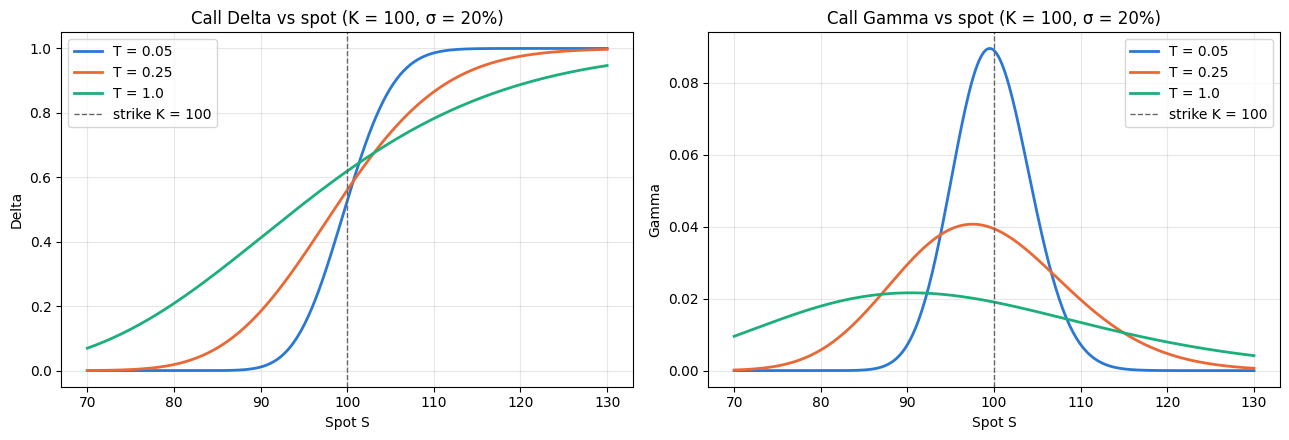

In [14]:
S_grid = np.linspace(70, 130, 300)
maturities = [0.05, 0.25, 1.0]                           # about 18 days, 3 months, 1 year
colors = ["#2a78d6", "#eb6834", "#1baf7a"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for T_, c in zip(maturities, colors):
    g = bs_greeks(S_grid, 100, T_, r, 0.0, 0.20, "call")
    axes[0].plot(S_grid, g["delta"], color=c, lw=2, label=f"T = {T_}")
    axes[1].plot(S_grid, g["gamma"], color=c, lw=2, label=f"T = {T_}")

for ax, name in zip(axes, ["Delta", "Gamma"]):
    ax.axvline(100, color="0.4", ls="--", lw=1, label="strike K = 100")
    ax.set_title(f"Call {name} vs spot (K = 100, σ = 20%)")
    ax.set_xlabel("Spot S")
    ax.set_ylabel(name)
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "day2_delta_gamma.png", dpi=150)
plt.show()

**How to read it**
- **Delta** goes from 0 (deep OTM: the call barely reacts) to 1 (deep ITM: the call moves like the
  stock). At the strike it is a bit above 0.5 (≈ 0.53 for $T = 0.05$, ≈ 0.62 for $T = 1$), because
  $d_1$ includes the positive term $(r + \tfrac12\sigma^2)T$. The **shorter** the maturity, the
  **steeper** the S-curve: with little time left, the option is almost either "worth something" or
  "worth nothing".
- **Gamma** is the slope of Delta, so it peaks where Delta is steepest. For short maturities that is
  right at the strike; for $T = 1$ the peak is lower, wider and sits below $K$ (around $S \approx 90$).
  As maturity shrinks the peak gets **taller, narrower and moves to the strike**. Short-dated ATM options are the hardest to hedge,
  because Delta changes very fast.

## 7. Bridge to Day 3: Price Is Increasing in $\sigma$

Implied volatility answers: *which $\sigma$ makes `bs_price` equal the market price?* That question has
exactly one answer only if the price **always rises** with $\sigma$. We check this visually for the test
call from Section 5 (chosen inputs, not market data).

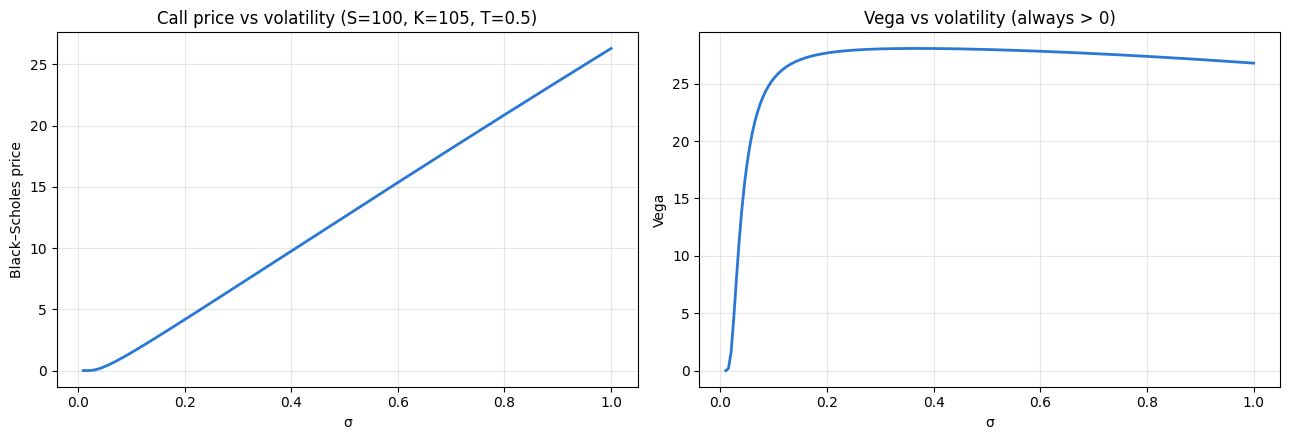

smallest vega on the grid = 0.0003  (> 0, so the price curve never goes down)


In [15]:
sig_grid = np.linspace(0.01, 1.0, 200)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(sig_grid, bs_price(tS, tK, tT, tr, tq, sig_grid, "call"), color="#2a78d6", lw=2)
axes[0].set_title("Call price vs volatility (S=100, K=105, T=0.5)")
axes[0].set_xlabel("σ")
axes[0].set_ylabel("Black–Scholes price")
axes[1].plot(sig_grid, bs_greeks(tS, tK, tT, tr, tq, sig_grid, "call")["vega"], color="#2a78d6", lw=2)
axes[1].set_title("Vega vs volatility (always > 0)")
axes[1].set_xlabel("σ")
axes[1].set_ylabel("Vega")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / "day2_price_vs_sigma.png", dpi=150)
plt.show()

v = bs_greeks(tS, tK, tT, tr, tq, sig_grid, "call")["vega"]
print(f"smallest vega on the grid = {v.min():.4f}  (> 0, so the price curve never goes down)")

**How to read it.** The price curve only goes **up** as $\sigma$ grows, because its slope — Vega — is
positive everywhere. So any market price between the lowest and highest point of this curve is hit by
**one and only one** $\sigma$. Day 3 finds that $\sigma$ numerically for every option.

Notice that Vega is **small at very low $\sigma$** for this OTM option: there the curve is flat, so a small
price error moves the implied σ a lot. That is the same problem stale prices create.

## 8. Day 2 Summary

**What was done today**
1. Loaded `clean_SPY.csv`, `clean_AAPL.csv` and `r` from `market_meta.json` — no yfinance.
2. Checked the data: no duplicate rows or contracts, missing values only in `volume`, `T` confirmed in
   years (calendar days / 365).
3. Found that `mid` equals `lastPrice` on every row (market closed at download), that almost all bids
   and asks are 0, and that `iv_yahoo` mostly holds placeholder values.
4. Built a vectorised `bs_price` and `bs_greeks`, checked them against a textbook example, and proved
   them correct with put–call parity, finite-difference and Monte Carlo tests.
5. Plotted Delta and Gamma vs spot, and showed that price rises with $\sigma$ (Vega > 0).

**Files produced:** `figures/day2_delta_gamma.png`, `figures/day2_price_vs_sigma.png`.

### Decisions needed before Day 3
| Decision | Options | Why it matters |
|---|---|---|
| **Which prices to invert** | (a) re-download during US trading hours (≈ 20:30–03:00 Phnom Penh time) with `REFRESH = True` in Notebook 01, so `mid` is a real bid–ask mid; (b) keep this snapshot and invert `lastPrice`, clearly labelled as stale | IV is only as good as the price we feed it; section 2.2 shows last trades above the ask |
| **Dividend yield $q$** | estimate it from put–call parity (implied forward, Day 3 plan) | not measured yet; we will not guess it |
| **Benchmark** | compare with `iv_yahoo` only where a live quote exists | most `iv_yahoo` values in this snapshot are placeholders |

**Next (Day 3):** implied forward and implied volatility.